# QPM 2026-2027 — Notebook 01: Managing Financial Data (Chapter 1)

**EDHEC · Quantitative Portfolio Management (Prof. R. Uppal) · Personal study notebook**

This notebook goes through Chapter 1 hands-on. Each section has the same structure:

> 📖 **Theory** (the formula from the slides) → 🧪 **Experiment** (simulation where we know the truth) → 💡 **Takeaway** → ✍️ **Exam-ready code**

**Contents**
1. Mean-variance weights: $N=1$ and $N>1$
2. The central problem: estimation error in $E[R]$ and $V[R]$
3. Prices and returns: gross, net, excess, log, compound
4. Distribution of returns: lognormality and fat tails
5. Data pitfalls: corporate actions and survivorship bias
6. Real data: Yahoo! Finance, Fama-French, macro predictors
7. Quiz-style questions

*Section 6 downloads data from the internet (works in Colab / on your laptop). If the download fails, the notebook automatically switches to simulated data so that everything still runs.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 4)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Mean-variance weights

### 1.1 One risky asset

📖 An investor with risk aversion $\gamma$ chooses the fraction $w_1$ of wealth in one risky asset, the rest in the risk-free asset:

$$ w_1 = \frac{1}{\gamma}\,\frac{E[R_1]-R_f}{V[R_1]}. $$

It comes from maximising the mean-variance objective $\;R_f + w(E[R_1]-R_f) - \frac{\gamma}{2}w^2 V[R_1]$.

🧪 Let's plot the objective and check that its maximum sits exactly at the formula.

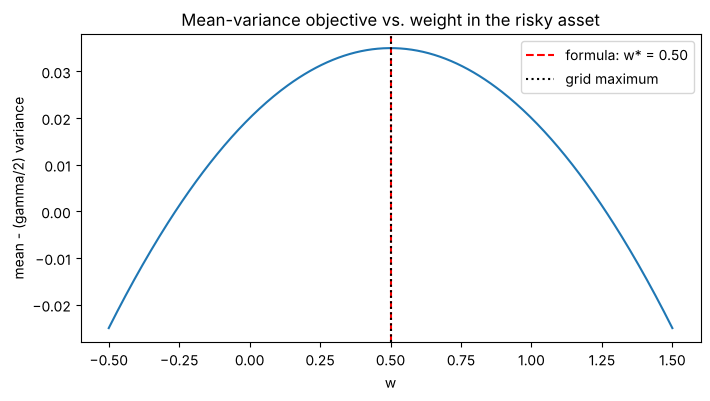

In [2]:
def mv_weight_1(premium, vol, gamma):
    # Optimal weight in a single risky asset
    return premium / (gamma * vol**2)

premium, vol, gamma, rf = 0.06, 0.20, 3, 0.02
w_grid = np.linspace(-0.5, 1.5, 401)
objective = rf + w_grid * premium - gamma / 2 * w_grid**2 * vol**2

w_star = mv_weight_1(premium, vol, gamma)
plt.plot(w_grid, objective)
plt.axvline(w_star, color="red", ls="--", label=f"formula: w* = {w_star:.2f}")
plt.axvline(w_grid[objective.argmax()], color="k", ls=":", label="grid maximum")
plt.title("Mean-variance objective vs. weight in the risky asset")
plt.xlabel("w"); plt.ylabel("mean - (gamma/2) variance"); plt.legend(); plt.show()

💡 **Intuition: every formula must make sense** (the professor insists on this). Let's look at the three comparative statics one at a time.

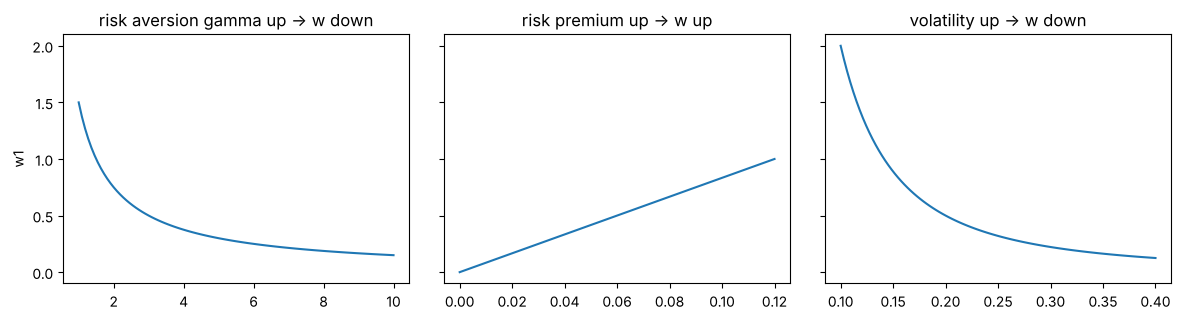

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
g = np.linspace(1, 10, 100)
ax[0].plot(g, mv_weight_1(0.06, 0.20, g)); ax[0].set_title("risk aversion gamma up -> w down")
p = np.linspace(0, 0.12, 100)
ax[1].plot(p, mv_weight_1(p, 0.20, 3)); ax[1].set_title("risk premium up -> w up")
s = np.linspace(0.10, 0.40, 100)
ax[2].plot(s, mv_weight_1(0.06, s, 3)); ax[2].set_title("volatility up -> w down")
ax[0].set_ylabel("w1")
plt.tight_layout(); plt.show()

### 1.2 Many risky assets

📖 The **key expression of the course**:

$$ w=\frac{1}{\gamma}V[R]^{-1}\big(E[R]-R_f\mathbf 1_N\big). $$

$V^{-1}$ takes **correlations** into account: an asset that is highly correlated with others can get a *negative* weight even if its expected return is positive (it is used as a hedge).

In [4]:
def mv_weights(mu, V, rf, gamma):
    # Mean-variance weights in N risky assets; rest in the risk-free asset
    return np.linalg.solve(V, mu - rf * np.ones(len(mu))) / gamma

names = ["Equity US", "Equity EU", "Bonds"]
mu = np.array([0.08, 0.075, 0.035])
vol = np.array([0.16, 0.18, 0.06])
corr = np.array([[1.0, 0.85, 0.1],
                 [0.85, 1.0, 0.1],
                 [0.1, 0.1, 1.0]])
V = np.outer(vol, vol) * corr

w = mv_weights(mu, V, rf=0.02, gamma=3)
pd.DataFrame({"E[R]": mu, "vol": vol, "MV weight": w}, index=names)

,E[R],vol,MV weight
Equity US,0.080,0.16,0.8412
Equity EU,0.075,0.18,-0.1096
Bonds,0.035,0.06,1.1975


💡 EU equity has a positive premium (5.5%), yet it gets a **short** position: it is 85% correlated with US equity, which offers a slightly better risk/return. The optimiser shorts EU to hedge US. This is a first sign of how *sensitive* MV weights are: small differences in inputs lead to big, extreme positions. Try changing `mu[1]` from 0.075 to 0.08 and watch the weights move.

In [5]:
for m in [0.070, 0.075, 0.080, 0.085]:
    mu_test = mu.copy(); mu_test[1] = m
    print(f"E[R_EU] = {m:.3f} -> weights {mv_weights(mu_test, V, 0.02, 3).round(2)}")

E[R_EU] = 0.070 -> weights [ 1.02 -0.3   1.21]
E[R_EU] = 0.075 -> weights [ 0.84 -0.11  1.2 ]
E[R_EU] = 0.080 -> weights [0.66 0.08 1.19]
E[R_EU] = 0.085 -> weights [0.49 0.26 1.18]


## 2. The central problem: estimation error

We never know $E[R]$ and $V[R]$: we **estimate** them. The rest of the course is about estimating them better. Chapter 1 explains why it is hard.

### 2.1 The mean: sampling more often does not help

📖 For log returns, $\ln R_{0,T} = p_T - p_0$: **only the first and last prices matter**. Daily data over 10 years contain no more information about the mean than two prices 10 years apart.

🧪 Python exercise 3 from the slides: 2,000 samples of 10 years, true $\mu=8\%$, $\sigma=20\%$.

In [6]:
rng = np.random.default_rng(3)
M, years, d = 2000, 10, 252
mu_true, sigma_true = 0.08, 0.20
r = rng.normal(mu_true / d, sigma_true / np.sqrt(d), size=(M, years * d))

k = {"daily": 1, "monthly": 21, "annual": 252}
rk = {f: r.reshape(M, -1, k[f]).sum(axis=2) for f in k}     # aggregate log returns
n = {f: d // k[f] for f in k}                               # observations per year

mean_hat = {f: rk[f].mean(axis=1) * n[f] for f in k}
vol_hat = {f: rk[f].std(axis=1, ddof=1) * np.sqrt(n[f]) for f in k}
table = pd.DataFrame({"T": [rk[f].shape[1] for f in k],
                      "SE of mean": [mean_hat[f].std() for f in k],
                      "SE of vol": [vol_hat[f].std() for f in k]}, index=list(k))
table

,T,SE of mean,SE of vol
daily,2520,0.0632,0.0028
monthly,120,0.0632,0.0126
annual,10,0.0632,0.0460


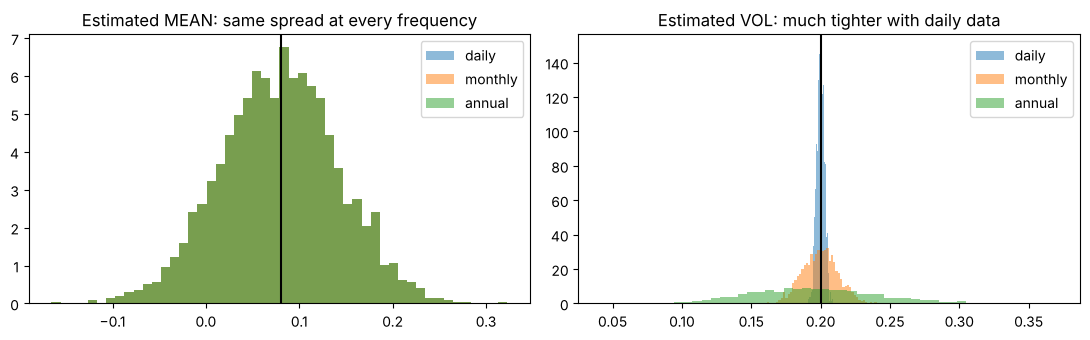

Theory: SE(mean) = sigma/sqrt(years) = 0.06324555320336758
Theory: SE(vol, daily) ~ sigma/sqrt(2*T) = 0.0028171808490950554


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for f in k:
    ax[0].hist(mean_hat[f], bins=50, alpha=0.5, label=f, density=True)
    ax[1].hist(vol_hat[f], bins=50, alpha=0.5, label=f, density=True)
ax[0].axvline(mu_true, color="k"); ax[0].set_title("Estimated MEAN: same spread at every frequency")
ax[1].axvline(sigma_true, color="k"); ax[1].set_title("Estimated VOL: much tighter with daily data")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

print("Theory: SE(mean) = sigma/sqrt(years) =", sigma_true / np.sqrt(years))
print("Theory: SE(vol, daily) ~ sigma/sqrt(2*T) =", sigma_true / np.sqrt(2 * years * d))

💡 **Takeaway:** the SE of the mean is 6.3% *regardless of frequency*. A 95% confidence interval is about 8% ± 12.6%: after 10 years we cannot even say whether the mean is positive. Volatility, instead, becomes precise with high-frequency data.

**How many years would we need?** To get SE(mean) = 1% with σ = 20% we need $(0.20/0.01)^2 = 400$ years!

In [8]:
target_se = np.array([0.05, 0.02, 0.01])
print(pd.DataFrame({"target SE": target_se,
                    "years needed": (sigma_true / target_se) ** 2}))

   target SE  years needed
0       0.05          16.0
1       0.02         100.0
2       0.01         400.0


### 2.2 The covariance matrix: too many parameters

📖 $V[R]$ has $N(N+1)/2$ parameters. With $N$ large relative to $T$, the sample covariance matrix is **ill-conditioned**: its smallest eigenvalues are biased towards zero, so $V^{-1}$ explodes in those directions.

🧪 Python exercise 1: $N$ identical assets (vol 20%, correlation 0.3), $T=60$ months. True GMV weights are all $1/N$.

In [9]:
rng = np.random.default_rng(1)
T = 60
sd = 0.20 / np.sqrt(12)
rho = 0.3
Ns = [5, 10, 25, 50]

V_true = {N: sd**2 * (rho * np.ones((N, N)) + (1 - rho) * np.eye(N)) for N in Ns}
R_sim = {N: rng.multivariate_normal(np.zeros(N), V_true[N], size=T) for N in Ns}
V_hat = {N: np.cov(R_sim[N], rowvar=False) for N in Ns}

w_gmv = {N: np.linalg.solve(V_hat[N], np.ones(N)) for N in Ns}
w_gmv = {N: w_gmv[N] / w_gmv[N].sum() for N in Ns}
pd.DataFrame({"N(N+1)/2 params": [N * (N + 1) // 2 for N in Ns],
              "cond(V)": [np.linalg.cond(V_true[N]) for N in Ns],
              "cond(Vhat)": [np.linalg.cond(V_hat[N]) for N in Ns],
              "true w": [1 / N for N in Ns],
              "min w": [w_gmv[N].min() for N in Ns],
              "max w": [w_gmv[N].max() for N in Ns]}, index=Ns)

,N(N+1)/2 params,cond(V),cond(Vhat),true w,min w,max w
5,15,3.1429,7.2158,0.20,0.0533,0.3776
10,55,5.2857,22.1228,0.10,-0.0397,0.2769
25,325,11.7143,61.0129,0.04,-0.1315,0.2585
50,1275,22.4286,1864.2556,0.02,-0.3882,0.4651


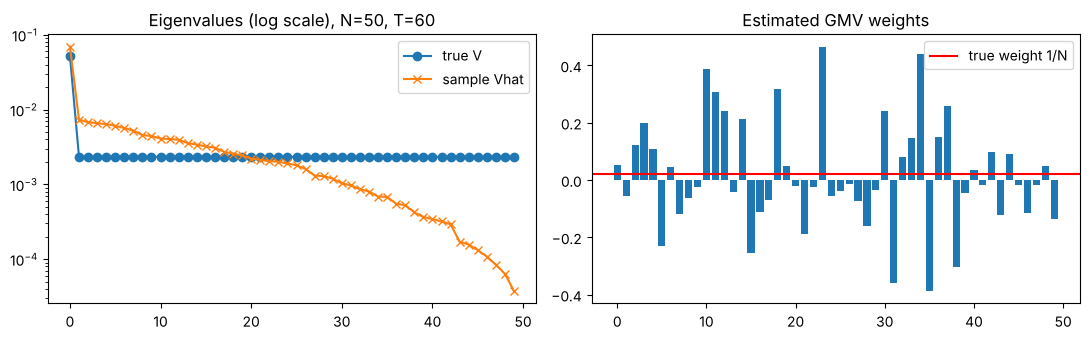

In [10]:
N = 50
ev_true = np.sort(np.linalg.eigvalsh(V_true[N]))[::-1]
ev_hat = np.sort(np.linalg.eigvalsh(V_hat[N]))[::-1]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].semilogy(ev_true, "o-", label="true V"); ax[0].semilogy(ev_hat, "x-", label="sample Vhat")
ax[0].set_title("Eigenvalues (log scale), N=50, T=60"); ax[0].legend()
ax[1].bar(range(N), w_gmv[N]); ax[1].axhline(1 / N, color="red", label="true weight 1/N")
ax[1].set_title("Estimated GMV weights"); ax[1].legend()
plt.tight_layout(); plt.show()

💡 The true matrix has one big eigenvalue (the common "market" factor) and 49 equal small ones. The sample matrix spreads them out: the smallest sample eigenvalues are much too small, so $\hat V^{-1}$ is huge in those directions → extreme long/short weights. **This is why sample MV portfolios perform badly out of sample** (Chapters 3–4).

### 2.3 How unstable are estimated MV weights?

🧪 Our own experiment (not in the slides): take the 3-asset example of §1.2 as the truth, draw 1,000 samples of 10 years of monthly data, compute the sample MV weights in each, and look at their distribution.

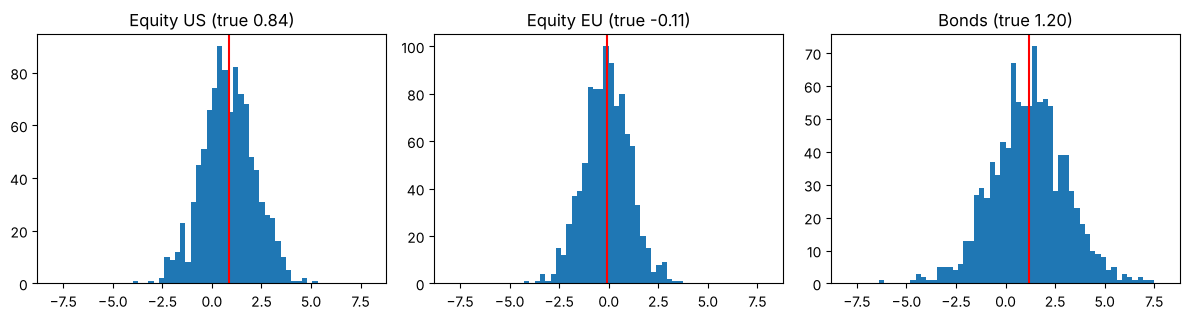

           true  mean est.  std est.  5th pct  95th pct
Equity US  0.84       0.84      1.31    -1.41      3.05
Equity EU -0.11      -0.10      1.14    -1.98      1.76
Bonds      1.20       1.17      1.88    -1.76      4.20


In [11]:
rng = np.random.default_rng(10)
n_samples, T = 1000, 120
w_true = mv_weights(mu, V, 0.02, 3)
W = np.empty((n_samples, 3))
for s in range(n_samples):
    Rs = rng.multivariate_normal(mu / 12, V / 12, size=T)
    W[s] = mv_weights(Rs.mean(0) * 12, np.cov(Rs, rowvar=False) * 12, 0.02, 3)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for i in range(3):
    ax[i].hist(W[:, i], bins=60, range=(-8, 8))
    ax[i].axvline(w_true[i], color="red")
    ax[i].set_title(f"{names[i]} (true {w_true[i]:.2f})")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"true": w_true, "mean est.": W.mean(0), "std est.": W.std(0),
                    "5th pct": np.percentile(W, 5, axis=0), "95th pct": np.percentile(W, 95, axis=0)},
                   index=names).round(2))

💡 The true weights are the red lines, but with 10 years of data the estimates are spread over several units: a standard deviation above 1 means that a "true" position of −11% in EU equity can easily come out as −200% or +200%. The error comes mostly from the **means**: $V^{-1}$ multiplies the noisy estimate of $E[R]$ and amplifies its error.

🧪 **Check:** repeat with the *true* means but *estimated* covariance. The weights become much more stable, which confirms that the means are the main culprit.

In [12]:
rng = np.random.default_rng(10)
W_trueMu = np.empty((n_samples, 3))
for s in range(n_samples):
    Rs = rng.multivariate_normal(mu / 12, V / 12, size=T)
    W_trueMu[s] = mv_weights(mu, np.cov(Rs, rowvar=False) * 12, 0.02, 3)
print("Std of weights, estimated mu + estimated V:", W.std(0).round(2))
print("Std of weights, TRUE mu      + estimated V:", W_trueMu.std(0).round(2))

Std of weights, estimated mu + estimated V: [1.31 1.14 1.88]
Std of weights, TRUE mu      + estimated V: [0.18 0.14 0.26]


## 3. Prices and returns

📖 Definitions

| | Formula | Notes |
|---|---|---|
| Gross | $R_t = P_t/P_{t-1}$ | aggregates **across assets**: $R_p=\sum w_n R_n$ |
| Net | $r_t = R_t - 1$ | |
| Excess | $R_t - R_{t,f}$ | gross excess = net excess |
| Log | $\ln R_t = p_t - p_{t-1}$ | aggregates **over time**: $\ln R(h)=\sum \ln R_t$ |
| With dividends | $R_t=(P_t+D_t)/P_{t-1}$ | |

🧪 Python exercise 4: three properties of simple vs. log returns.

In [13]:
rng = np.random.default_rng(4)
T = 120
R = 1 + rng.normal(0.008, 0.05, size=(T, 2))   # gross monthly returns, 2 assets
r = np.log(R)

# (1) compounding: product of gross = exp(sum of logs)
print("prod(R)    =", R[:, 0].prod().round(6))
print("exp(sum r) =", np.exp(r[:, 0].sum()).round(6))

# (2) arithmetic vs geometric mean
arith = 12 * (R[:, 0] - 1).mean()
geom = R[:, 0].prod() ** (12 / T) - 1
print(f"arithmetic {arith:.4f}  geometric {geom:.4f}  gap {arith-geom:.4f}  sigma^2/2 {12*(R[:,0]-1).var()/2:.4f}")

# (3) log of portfolio return vs weighted sum of logs
w2 = np.array([0.6, 0.4])
gap_m = np.abs(np.log(R @ w2) - r @ w2).mean()
Ra = R.reshape(10, 12, 2).prod(axis=1)
gap_a = np.abs(np.log(Ra @ w2) - np.log(Ra) @ w2).mean()
print(f"mean gap: monthly {gap_m:.5f}, annual {gap_a:.5f}")

prod(R)    = 2.079249
exp(sum r) = 2.079249
arithmetic 0.0892  geometric 0.0759  gap 0.0132  sigma^2/2 0.0157
mean gap: monthly 0.00066, annual 0.00742


💡 **Arithmetic vs. geometric mean, the classic example:** +50% then −50%. The arithmetic mean is 0%, but you lose money.

In [14]:
path = np.array([1.5, 0.5])
print("Arithmetic mean of net returns:", (path - 1).mean())
print("Final wealth from $1         :", path.prod())
print("Geometric mean per period    :", path.prod() ** 0.5 - 1)

Arithmetic mean of net returns: 0.0
Final wealth from $1         : 0.75
Geometric mean per period    : -0.1339745962155614


🧪 **Volatility drag:** how does the gap between arithmetic and geometric means grow with volatility? Theory says ≈ $\sigma^2/2$.

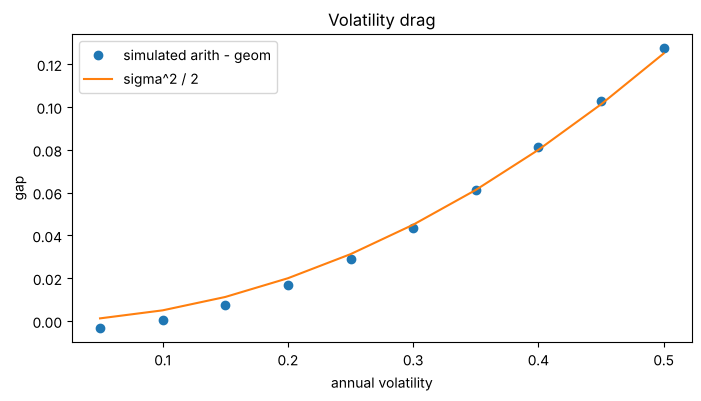

In [15]:
rng = np.random.default_rng(11)
vols = np.linspace(0.05, 0.50, 10)
gaps = []
for s in vols:
    Rm = 1 + rng.normal(0.10 / 12, s / np.sqrt(12), size=200_000)
    a = 12 * (Rm - 1).mean()
    g = np.exp(12 * np.log(Rm).mean()) - 1
    gaps.append(a - g)
plt.plot(vols, gaps, "o", label="simulated arith - geom")
plt.plot(vols, vols**2 / 2, label="sigma^2 / 2")
plt.xlabel("annual volatility"); plt.ylabel("gap"); plt.legend(); plt.title("Volatility drag"); plt.show()

### Tidy data and returns: the `groupby` trap (Python exercise 2)

In [16]:
rng = np.random.default_rng(2)
dates = pd.date_range("2024-01-31", periods=24, freq="ME")
ret = rng.normal(0.01, 0.06, size=(24, 3))
prices_wide = pd.DataFrame(100 * np.cumprod(1 + ret, axis=0), index=dates, columns=["AAA", "BBB", "CCC"])
prices_wide.index.name = "date"

prices = (prices_wide.reset_index()
          .melt(id_vars="date", var_name="symbol", value_name="price")
          .sort_values(["symbol", "date"]))
prices["ret_wrong"] = prices["price"].pct_change()
prices["ret"] = prices.groupby("symbol")["price"].pct_change()
display(prices.iloc[22:26])

ret_wide = prices.pivot(index="date", columns="symbol", values="ret")
ret_wide.dropna().corr().round(2)

,date,symbol,price,ret_wrong,ret
22,2025-11-30,AAA,72.2815,-0.0818,-0.0818
23,2025-12-31,AAA,73.3244,0.0144,0.0144
24,2024-01-31,BBB,97.8635,0.3347,NaN
25,2024-02-29,BBB,109.4097,0.1180,0.1180


symbol,AAA,BBB,CCC
symbol,,,
AAA,1.00,0.01,-0.09
BBB,0.01,1.00,0.16
CCC,-0.09,0.16,1.00


## 4. Distribution of returns

### 4.1 Lognormal returns

📖 If $\ln R\sim\mathcal N(\mu,\sigma^2)$ then $E[R]=e^{\mu+\sigma^2/2}$ and $V[R]=e^{2\mu+\sigma^2}(e^{\sigma^2}-1)$. Gross returns are bounded below by 0 (**limited liability**).

🧪 Check the formulas by simulation.

E[R]: simulated 1.08314  formula 1.08329


V[R]: simulated 0.04783  formula 0.04789
Minimum gross return: 0.3891 (never below 0)


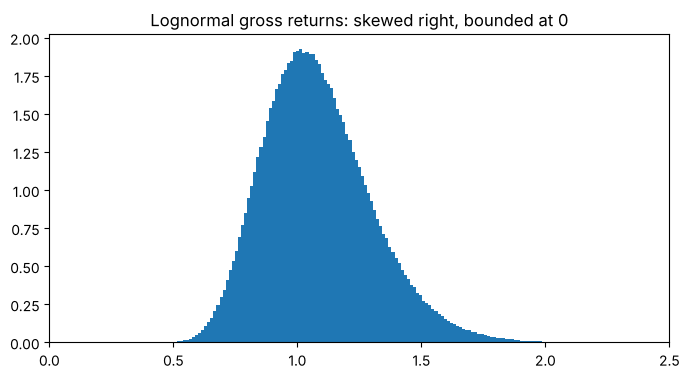

In [17]:
rng = np.random.default_rng(12)
mu_l, s_l = 0.06, 0.20
Rl = np.exp(rng.normal(mu_l, s_l, size=1_000_000))
print(f"E[R]: simulated {Rl.mean():.5f}  formula {np.exp(mu_l + s_l**2/2):.5f}")
print(f"V[R]: simulated {Rl.var():.5f}  formula {np.exp(2*mu_l + s_l**2)*(np.exp(s_l**2)-1):.5f}")
print("Minimum gross return:", Rl.min().round(4), "(never below 0)")

plt.hist(Rl, bins=200, density=True)
plt.title("Lognormal gross returns: skewed right, bounded at 0"); plt.xlim(0, 2.5); plt.show()

### 4.2 Fat tails (Python exercise 5)

📖 Normal: skewness 0, kurtosis 3. Under Normality, $\hat S\sim\mathcal N(0,6/T)$, $\hat K\sim\mathcal N(3,24/T)$. Jarque-Bera: $JB=T\big[\hat S^2/6+(\hat K-3)^2/24\big]\sim\chi^2_2$.

In [18]:
rng = np.random.default_rng(5)
T, nu = 21 * 500, 5
z = rng.standard_t(nu, size=T) / np.sqrt(nu / (nu - 2))   # unit variance t(5)
daily = 0.01 * z
monthly = daily.reshape(-1, 21).sum(axis=1)
x = {"daily": daily, "monthly": monthly}

def jb_by_hand(v):
    S, K = stats.skew(v), stats.kurtosis(v, fisher=False)
    jb = len(v) * (S**2 / 6 + (K - 3)**2 / 24)
    return jb, stats.chi2.sf(jb, df=2)

n4 = {f: np.sum(np.abs(x[f] - x[f].mean()) > 4 * x[f].std()) for f in x}
pd.DataFrame({"T": [len(x[f]) for f in x],
              "skew": [stats.skew(x[f]) for f in x],
              "kurt": [stats.kurtosis(x[f], fisher=False) for f in x],
              "JB p (scipy)": [stats.jarque_bera(x[f]).pvalue for f in x],
              "JB p (by hand)": [jb_by_hand(x[f])[1] for f in x],
              "4-sigma moves": [n4[f] for f in x],
              "expected if Normal": [len(x[f]) * 2 * stats.norm.sf(4) for f in x]}, index=list(x))

,T,skew,kurt,JB p (scipy),JB p (by hand),4-sigma moves,expected if Normal
daily,10500,-0.1044,7.2563,0.0000,0.0000,40,0.6651
monthly,500,0.0757,2.9323,0.7507,0.7507,0,0.0317


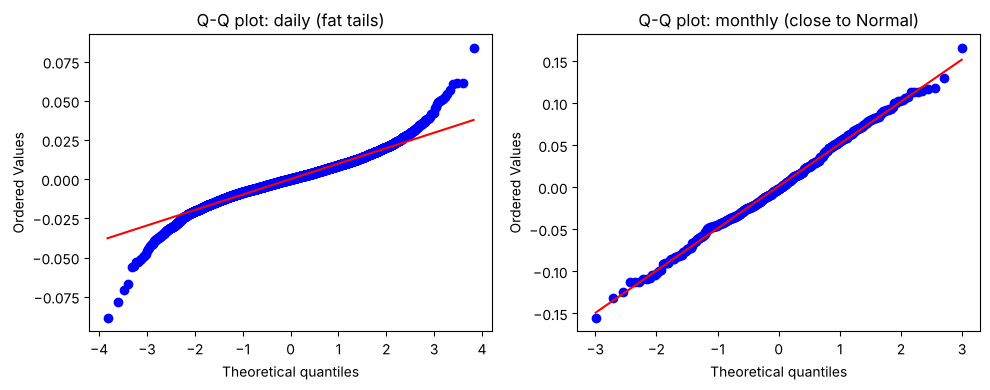

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(daily, dist="norm", plot=ax[0]); ax[0].set_title("Q-Q plot: daily (fat tails)")
stats.probplot(monthly, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot: monthly (close to Normal)")
plt.tight_layout(); plt.show()

💡 In the Q-Q plot, the daily points bend away from the line at both ends: extreme moves are far more frequent than the Normal predicts. Summing 21 days gives monthly returns that look Normal (central limit theorem). *Caveat from the slides:* in real data volatility changes over time, so real monthly returns are still somewhat fat-tailed.

## 5. Data pitfalls

### 5.1 Splits and dividends: use adjusted prices (Python exercise 6)

,close,adjusted,raw_ret,adj_ret
150,102.2968,101.4969,-0.7536,-0.0143
200,126.8846,126.8846,-0.0280,-0.0203


Largest error of adjusted returns: 3.8380756905986857e-16


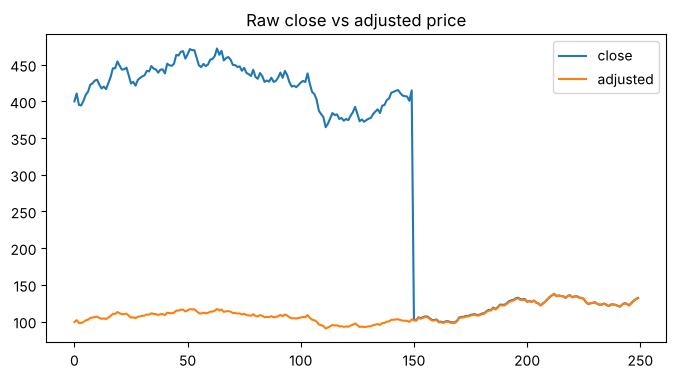

In [20]:
rng = np.random.default_rng(6)
n = 250
true_ret = rng.normal(0.0004, 0.015, size=n); true_ret[0] = 0.0
split_day, ratio = 150, 4
div_day, div = 200, 1.00
G = np.cumprod(1 + true_ret)
day = np.arange(n)
shares = np.where(day >= split_day, ratio, 1)
close = 400 * G / shares - div * (G / G[div_day]) * (day >= div_day)

f = np.ones(n)
f[split_day] = 1 / ratio
f[div_day] = close[div_day] / (close[div_day] + div)
adj = np.append(np.cumprod(f[::-1])[::-1][1:], 1.0)     # product of factors of all LATER events
df = pd.DataFrame({"close": close, "adjusted": close * adj})
df["raw_ret"] = df["close"].pct_change()
df["adj_ret"] = df["adjusted"].pct_change()
display(df.loc[[split_day, div_day]].round(4))
print("Largest error of adjusted returns:", np.abs(df["adj_ret"].values[1:] - true_ret[1:]).max())

df[["close", "adjusted"]].plot(title="Raw close vs adjusted price"); plt.show()

### 5.2 Survivorship bias (Python exercise 7)

Using **today's** index constituents to backtest keeps only the winners.

🧪 We extend the slide example: how does the bias depend on the delisting threshold?

In [21]:
def survivorship(threshold, N=1000, T=120, seed=7):
    rng = np.random.default_rng(seed)
    ret = rng.normal(0.008, 0.12, size=(N, T))
    price = np.cumprod(1 + ret, axis=1)
    dead = np.maximum.accumulate(price < threshold, axis=1)
    listed = np.hstack([np.ones((N, 1), bool), ~dead[:, :-1]])
    survivor = ~dead[:, -1]
    all_firms = np.nanmean(np.where(listed, ret, np.nan), axis=0).mean()
    return survivor.mean(), all_firms, ret[survivor].mean()

rows = [(th, *survivorship(th)) for th in [0.1, 0.2, 0.3, 0.4, 0.5]]
res = pd.DataFrame(rows, columns=["delist below", "share surviving", "mean all listed", "mean survivors"])
res["annual bias"] = 12 * (res["mean survivors"] - 0.008)
res

,delist below,share surviving,mean all listed,mean survivors,annual bias
0,0.1,0.924,0.0080,0.0096,0.0190
1,0.2,0.786,0.0080,0.0117,0.0449
2,0.3,0.663,0.0079,0.0132,0.0630
3,0.4,0.548,0.0081,0.0148,0.0817
4,0.5,0.438,0.0083,0.0164,0.1013


💡 With a 30% threshold (the slide case), survivors earn 1.32%/month vs. a true 0.8%: about **6% per year** of fake performance. For backtests, use the constituents **at each past date** (e.g. CRSP), not today's.

## 6. Real data

Code adapted from the slides / Tidy Finance. Each download has a fallback to simulated data, so the notebook always runs.

Install once (in Colab these lines are enough):
```python
!pip install yfinance pandas-datareader
```

In [ ]:
def try_download(func, fallback, label):
    try:
        out = func()
        if out is None or len(out) == 0:
            raise ValueError("empty")
        print(f"OK: {label} downloaded ({len(out)} rows)")
        return out, True
    except Exception as e:
        print(f"Could not download {label} ({type(e).__name__}); using SIMULATED data instead.")
        return fallback(), False

### 6.1 Stock prices from Yahoo! Finance

📖 Use the **adjusted** price (corrected for splits and dividends). Then compute returns with `groupby("symbol")`.

In [ ]:
tickers = ["AAPL", "MSFT", "JPM", "XOM", "JNJ", "PG"]

def get_yahoo():
    import yfinance as yf
    raw = yf.download(tickers=tickers, start="2005-01-01", end="2024-12-31",
                      auto_adjust=False, progress=False)
    return (raw["Adj Close"].stack().dropna().rename("adjusted").reset_index()
            .rename(columns={"Date": "date", "Ticker": "symbol"}))

def simulate_prices():
    rng = np.random.default_rng(99)
    d = pd.bdate_range("2005-01-03", "2024-12-31")
    mus = np.array([0.20, 0.15, 0.10, 0.07, 0.08, 0.08]) / 252
    vols = np.array([0.32, 0.27, 0.32, 0.27, 0.17, 0.18]) / np.sqrt(252)
    C = 0.35 * np.ones((6, 6)) + 0.65 * np.eye(6)
    Rd = rng.multivariate_normal(mus, np.outer(vols, vols) * C, size=len(d))
    wide = pd.DataFrame(100 * np.cumprod(1 + Rd, axis=0), index=pd.Index(d, name="date"), columns=tickers)
    return wide.reset_index().melt(id_vars="date", var_name="symbol", value_name="adjusted")

prices, real_prices = try_download(get_yahoo, simulate_prices, "Yahoo! Finance prices")
prices.head()

In [ ]:
# Daily returns (tidy), then monthly returns by compounding
returns_daily = (prices
  .sort_values(["symbol", "date"])
  .assign(ret=lambda x: x.groupby("symbol")["adjusted"].pct_change())
  .dropna())

returns_monthly = (returns_daily
  .assign(month=lambda x: x["date"].dt.to_period("M").dt.to_timestamp())
  .groupby(["symbol", "month"])["ret"]
  .apply(lambda r: (1 + r).prod() - 1)
  .reset_index())

summary = (returns_monthly.groupby("symbol")["ret"]
  .agg(mean="mean", vol="std", skew="skew", kurt=lambda r: r.kurt() + 3)
  .assign(mean_ann=lambda x: 12 * x["mean"],
          vol_ann=lambda x: np.sqrt(12) * x["vol"],
          se_mean_ann=lambda x: x["vol_ann"] / np.sqrt(len(returns_monthly["month"].unique()) / 12)))
summary.round(3)

💡 Look at `se_mean_ann`: with ~20 years of data, the standard error of each annual mean is about 5–7%. Many differences in average returns across these stocks are **not statistically distinguishable**, which is exactly what §2 predicted.

### 6.2 Sample MV weights on real data

In [ ]:
ret_wide = returns_monthly.pivot(index="month", columns="symbol", values="ret").dropna()
mu_hat = ret_wide.mean().values * 12
V_hat = ret_wide.cov().values * 12

w_sample = mv_weights(mu_hat, V_hat, rf=0.02, gamma=5)
w_gmv = np.linalg.solve(V_hat, np.ones(len(mu_hat))); w_gmv /= w_gmv.sum()
pd.DataFrame({"mu_hat": mu_hat, "vol_hat": np.sqrt(np.diag(V_hat)),
              "MV (gamma=5)": w_sample, "GMV": w_gmv}, index=ret_wide.columns).round(3)

In [ ]:
# How sensitive are the weights to the sample period? Re-estimate on two halves.
half = len(ret_wide) // 2
pd.DataFrame({label: mv_weights(sub.mean().values * 12, sub.cov().values * 12, 0.02, 5)
              for label, sub in [("first half", ret_wide.iloc[:half]),
                                 ("second half", ret_wide.iloc[half:])]},
             index=ret_wide.columns).round(2)

💡 If the weights change a lot between the two halves, the sample MV portfolio is mostly fitting **noise** in the means. Chapters 3–4 study the fixes: constraints, shrinkage, GMV, Bayesian methods.

### 6.3 Fama-French factors (Ken French data library)

In [ ]:
start_date, end_date = "1963-07-01", "2024-12-31"

def get_ff3():
    import pandas_datareader as pdr
    raw = pdr.DataReader(name="F-F_Research_Data_Factors", data_source="famafrench",
                         start=start_date, end=end_date)[0]
    return (raw.divide(100)
            .reset_index(names="month")
            .assign(month=lambda x: pd.to_datetime(x["month"].astype(str)))
            .rename(str.lower, axis="columns")
            .rename(columns={"mkt-rf": "mkt_excess"}))

def simulate_ff3():
    rng = np.random.default_rng(3)
    m = pd.date_range(start_date, end_date, freq="MS")
    return pd.DataFrame({"month": m,
                         "mkt_excess": rng.normal(0.006, 0.045, len(m)),
                         "smb": rng.normal(0.002, 0.03, len(m)),
                         "hml": rng.normal(0.003, 0.03, len(m)),
                         "rf": np.full(len(m), 0.003)})

ff3, real_ff3 = try_download(get_ff3, simulate_ff3, "Fama-French 3 factors")
ff3.head()

In [ ]:
fac = ["mkt_excess", "smb", "hml"]
stats_ff = pd.DataFrame({
    "mean (ann.)": 12 * ff3[fac].mean(),
    "vol (ann.)": np.sqrt(12) * ff3[fac].std(),
    "Sharpe (ann.)": np.sqrt(12) * ff3[fac].mean() / ff3[fac].std(),
    "t-stat of mean": ff3[fac].mean() / (ff3[fac].std() / np.sqrt(len(ff3)))})
display(stats_ff.round(3))

(1 + ff3.set_index("month")[fac]).cumprod().plot(logy=True, title="Cumulative factor returns (log scale)")
plt.show()

💡 The **t-stat of the mean** = mean / (sd/√T). Even with 60 years of data, factor premia like SMB are hard to distinguish from zero. Estimation error again!

### 6.4 Macro data: CPI from FRED and real returns

In [ ]:
def get_cpi():
    import pandas_datareader as pdr
    return (pdr.DataReader(name="CPIAUCNS", data_source="fred", start=start_date, end=end_date)
            .reset_index(names="month")
            .rename(columns={"CPIAUCNS": "cpi"}))

def simulate_cpi():
    m = pd.date_range(start_date, end_date, freq="MS")
    rng = np.random.default_rng(4)
    return pd.DataFrame({"month": m, "cpi": 30 * np.cumprod(1 + rng.normal(0.003, 0.003, len(m)))})

cpi, real_cpi = try_download(get_cpi, simulate_cpi, "CPI from FRED")
cpi = cpi.assign(infl=lambda x: x["cpi"].pct_change())

mkt = (ff3.merge(cpi, on="month", how="inner")
          .assign(mkt=lambda x: x["mkt_excess"] + x["rf"],
                  mkt_real=lambda x: (1 + x["mkt"]) / (1 + x["infl"]) - 1)
          .dropna())
print("Nominal market return (ann.):", round(12 * mkt["mkt"].mean(), 4))
print("Real market return    (ann.):", round(12 * mkt["mkt_real"].mean(), 4))
print("Average inflation     (ann.):", round(12 * mkt["infl"].mean(), 4))

✍️ **Exam-ready: real return** $\;R^{real}=\dfrac{1+r^{nom}}{1+\pi}-1\approx r^{nom}-\pi$
```python
df["ret_real"] = (1 + df["ret"]) / (1 + df["infl"]) - 1
```

## 7. Quiz-style questions

Answer first, then open the solution.

**Q1.** You double the sampling frequency (weekly → daily) over the same 20 years. What happens to the standard error of the estimated annual mean? And of the volatility?
<details><summary>Solution</summary>The SE of the mean does not change (σ/√20 ≈ 4.5% for σ = 20%). The SE of the volatility falls.</details>

**Q2.** How many unique parameters does the covariance matrix of the S&P 500 constituents have?
<details><summary>Solution</summary>N(N+1)/2 = 500·501/2 = 125,250.</details>

**Q3.** Which returns aggregate linearly across assets, and which over time?
<details><summary>Solution</summary>Gross (simple) returns across assets: R_p = Σ w_n R_n. Log returns over time: ln R(h) = Σ ln R_t.</details>

**Q4.** The arithmetic average monthly return of a fund is 1%, its monthly volatility 6%. Approximate its geometric (compound) annual return.
<details><summary>Solution</summary>Annual arithmetic ≈ 12%, annual variance = 12·0.06² = 0.0432, so the geometric return ≈ 12% − 0.0432/2 ≈ 9.8%.</details>

**Q5.** A sample of 2,500 daily returns has kurtosis 6. Can you reject Normality?
<details><summary>Solution</summary>SE(K̂) = √(24/2500) ≈ 0.098, so z = (6−3)/0.098 ≈ 31: reject strongly.</details>

**Q6.** On the day of a 3-for-1 split, the raw close-to-close return is −66%. What is the true return if the adjusted return is +1%?
<details><summary>Solution</summary>+1%: the raw number reflects the split (price ÷ 3), not a loss for the investor.</details>

**Q7.** Write (by hand) the code to compute monthly returns from a tidy DataFrame of daily adjusted prices `prices[symbol, date, adjusted]`.
<details><summary>Solution</summary>

```python
monthly = (prices.sort_values(["symbol", "date"])
  .assign(ret=lambda x: x.groupby("symbol")["adjusted"].pct_change(),
          month=lambda x: x["date"].dt.to_period("M"))
  .groupby(["symbol", "month"])["ret"]
  .apply(lambda r: (1 + r).prod() - 1)
  .reset_index())
```
</details>

**Q8.** Why can survivorship bias make a backtest look better than reality? How do you avoid it?
<details><summary>Solution</summary>Today's constituents are firms that did well (losers were delisted). Use point-in-time constituents (e.g. CRSP) and include delisting returns.</details>